In [1]:
%load_ext autoreload
%autoreload 2
from CrocoDash.grid import Grid
from CrocoDash.topo import Topo
from CrocoDash.vgrid import VGrid
from pathlib import Path
from CrocoDash.case import Case

In [2]:
# CESM case (experiment) name
casename = "test.bgc.fix.1"

# CESM source root (Update this path accordingly!!!)
cesmroot ="/glade/u/home/manishrv/work/crocodile2026/CESM"

# Place where all your input files go 
inputdir = Path.home()/"scratch" / "croc_input" / casename
    
# CESM case directory
caseroot = Path.home() / "croc_cases" / casename

bathymetry_path = "/glade/derecho/scratch/manishrv/croc_input/bd.oo.10thdegree/ocnice/ocean_topog_open_ocean_nar_10_4ea79c.nc"
compset = "CR1850MARBL_JRA"

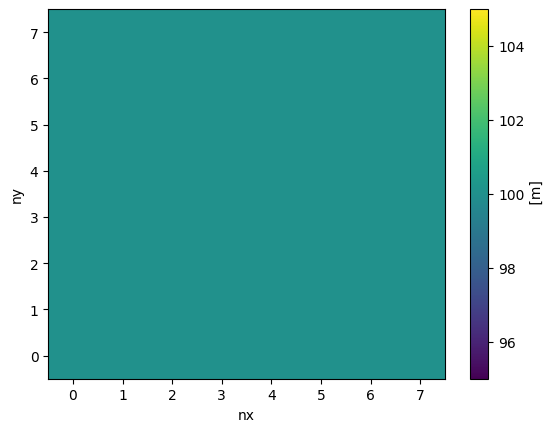

In [3]:

grid = Grid(
  resolution = 1/4, # in degrees
  xstart = 175, # min longitude in [0, 360]
  lenx = 2.0, # longitude extent in degrees
  ystart = 62.5, # min latitude in [-90, 90]
  leny = 2.0, # latitude extent in degrees
  name = "small_alaska",
)
topo = Topo(grid, 9)
topo.set_flat(100)
topo.depth.plot()
vgrid  = VGrid.hyperbolic(
    nk = 30,
    depth = topo.max_depth,
    ratio=5.0
)

In [4]:

case = Case(
    cesmroot = cesmroot,
    caseroot = caseroot,
    inputdir = inputdir,
    ocn_grid = grid,
    ocn_vgrid = vgrid,
    ocn_topo = topo,
    project = 'NCGD0011',
    override = True,
    machine = "derecho",
    compset = compset,
)

WARNING [CIME.XML.grids] Schema validity test fails for /glade/work/manishrv/crocodile2026/CESM/ccs_config/config_grids_nuopc.xml


Removing previous case files: /glade/u/home/manishrv/scratch/croc_input/test.bgc.fix.1
Removing previous case files: /glade/u/home/manishrv/croc_cases/test.bgc.fix.1
Removing previous case files: /glade/derecho/scratch/manishrv/test.bgc.fix.1
Creating case...

Running the create_newcase tool with the following command:

/glade/u/home/manishrv/work/crocodile2026/CESM/cime/scripts/create_newcase --compset CR1850MARBL_JRA --res USER_RES --case /glade/u/home/manishrv/croc_cases/test.bgc.fix.1 --machine derecho --run-unsupported --handle-preexisting-dirs a --pecount S --project NCGD0011 --non-local 

The create_newcase command was successful.

• Updating case xml variables to include newly generated ocean grid "small_alaska" with the following properties:
 nx: 8, ny: 8. ocean mesh: /glade/u/home/manishrv/scratch/croc_input/test.bgc.fix.1/ocn/ESMF_mesh_small_alaska_f645c8.nc.

./xmlchange OCN_GRID=small_alaska --non-local
./xmlchange OCN_NX=8 --non-local
./xmlchange OCN_NY=8 --non-local
./xm

In [5]:
case.configure_forcings(
    date_range = ["2000-01-01 00:00:00", "2000-01-03 00:00:00"],
    product_name = "reference_ocean",
    function_name="get_reference_ocean_data",
    marbl_ic_filepath = "/glade/campaign/collections/gdex/data/d651077/cesmdata/inputdata/ocn/mom/tx0.66v1/ecosys_jan_IC_omip_latlon_1x1_180W_c231221.nc"
)


INFO [CrocoDash.forcing.base] [REQUIRED] Activating StreamYears
INFO [CrocoDash.forcing.base] [REQUIRED] Activating BGC
INFO [CrocoDash.forcing.base] [REQUIRED] Activating BGCIC
INFO [CrocoDash.forcing.base] [REQUIRED] Activating BGCIronForcing
INFO [CrocoDash.forcing.base] [SKIP] BGCRiverNutrients incompatible with compset
INFO [CrocoDash.forcing.base] [SKIP] Chl incompatible with compset
INFO [CrocoDash.forcing.base] [SKIP] CICE incompatible with compset
INFO [CrocoDash.forcing.base] [REQUIRED] Activating conditions
INFO [CrocoDash.forcing.base] [SKIP] Runoff incompatible with compset
INFO [CrocoDash.forcing.base] [SKIP] tides missing args: ['tpxo_elevation_filepath', 'tpxo_velocity_filepath', 'tidal_constituents']
INFO [CrocoDash.forcing.base] [SKIP] WW3 incompatible with compset
INFO [CrocoDash.forcing.base] Configuring StreamYears


WARNING [CrocoDash.forcing.atm] DROF stream years left at CESM defaults: no active drof


Adding parameter changes to user_nl_datm_streams:

  ! Align CORE_IAF_JRA_1p5_2023 streams with the run dates (CrocoDash: CDEPS defaults to year_align=1)
  CORE_IAF_JRA_1p5_2023.GCGCS.PREC:year_first = 1998
  CORE_IAF_JRA_1p5_2023.GCGCS.PREC:year_last = 2001
  CORE_IAF_JRA_1p5_2023.GCGCS.PREC:year_align = 1998
  CORE_IAF_JRA_1p5_2023.GCGCS.PREC:datafiles = /glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1.5_noleap/JRA.v1.5.prec.TL319.1998.210504.nc,/glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1.5_noleap/JRA.v1.5.prec.TL319.1999.210504.nc,/glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1.5_noleap/JRA.v1.5.prec.TL319.2000.210504.nc,/glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1.5_noleap/JRA.v1.5.prec.TL319.2001.210504.nc
  CORE_IAF_JRA_1p5_2023.GISS.LWDN:year_first = 1998
  CORE_IAF_JRA_1p5_2023.GISS.LWDN:year_last = 2001
  CORE_IAF_JRA_1p5_2023.GISS.LWDN:year_align = 1998
  CORE_IAF_JRA_1p5_2023.GISS.LWDN:datafiles = /glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1